# Implementasi Neural Network Menggunakan Dataset CIFAR-10

## 1. Tujuan Praktikum
Praktikum ini bertujuan untuk memahami penerapan Neural Network dalam melakukan klasifikasi gambar menggunakan dataset yang berbeda dari contoh praktikum, yaitu CIFAR-10.

## 2. Dataset yang Digunakan
Dataset CIFAR-10 merupakan dataset gambar yang terdiri dari 10 kategori objek, yaitu pesawat, mobil, burung, kucing, rusa, anjing, katak, kuda, kapal, dan truk.

Setiap gambar memiliki ukuran 32 × 32 piksel dengan tiga channel warna RGB.

## 3. Metode yang Digunakan
Metode yang digunakan adalah Neural Network dengan arsitektur Sequential yang terdiri dari:

- Flatten sebagai input layer.
- Dense dengan 128 neuron dan aktivasi ReLU sebagai hidden layer.
- Dense dengan 10 neuron dan aktivasi Softmax sebagai output layer.

Optimizer yang digunakan adalah Adam dengan fungsi loss Sparse Categorical Crossentropy.

## 4. Tahapan Implementasi
Tahapan implementasi meliputi pengambilan dataset, normalisasi gambar, pembuatan model Neural Network, kompilasi model, pelatihan, evaluasi, visualisasi grafik, dan prediksi gambar.

## 5. Hasil dan Pembahasan
Bagian ini berisi hasil training, nilai test accuracy, test loss, grafik accuracy dan loss, serta contoh hasil prediksi gambar.
Hasil tersebut digunakan untuk mengetahui kemampuan model dalam mengklasifikasikan gambar ke dalam kategori yang sesuai.

## 6. Kesimpulan
Neural Network dapat diterapkan untuk melakukan klasifikasi gambar menggunakan dataset CIFAR-10. Proses pembelajaran dilakukan melalui training, kemudian performa model diamati melalui evaluasi dan hasil prediksi terhadap data pengujian.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10

# Load dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

print("Jumlah data training:", train_images.shape)
print("Jumlah data testing:", test_images.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2250s 13us/step
Jumlah data training: (50000, 32, 32, 3)
Jumlah data testing: (10000, 32, 32, 3)


Penjelasan:
- TensorFlow digunakan untuk membangun Neural Network.
- NumPy digunakan untuk operasi data.
- Matplotlib digunakan untuk menampilkan gambar dan grafik.
- CIFAR-10 digunakan sebagai dataset pengganti Fashion MNIST.

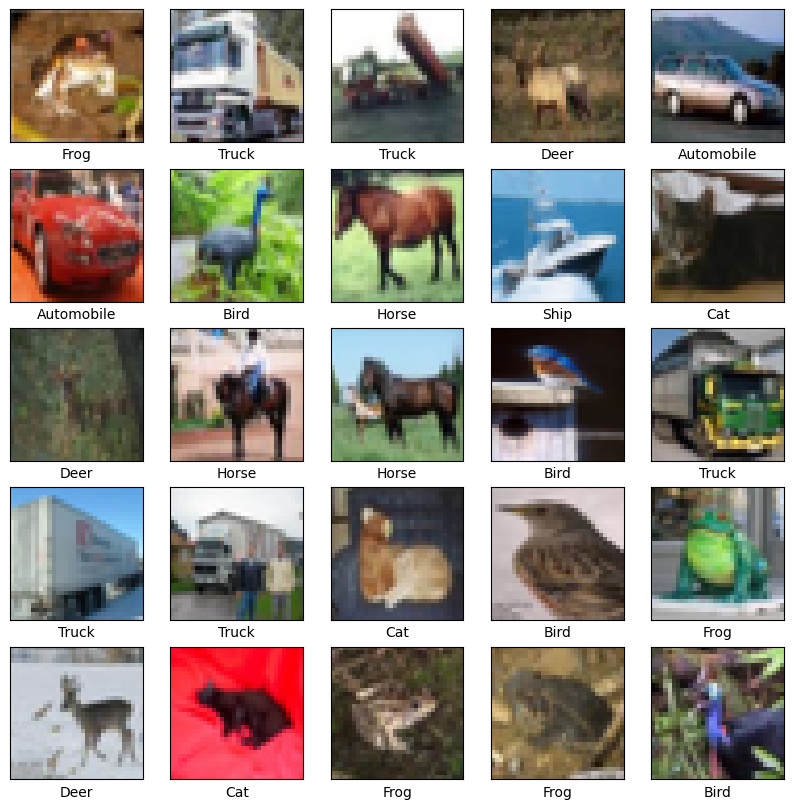

In [2]:
# Normalisasi nilai piksel menjadi 0 sampai 1
train_images = train_images / 255.0
test_images = test_images / 255.0

# Nama kategori
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Menampilkan 25 contoh gambar
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])

plt.show()

Penjelasan:

Normalisasi dilakukan dengan membagi nilai piksel dengan 255 agar nilainya berada di antara 0 sampai 1.
Tujuannya agar proses pembelajaran Neural Network lebih stabil.

In [3]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense

# Membuat model Neural Network
model = Sequential([
    Flatten(input_shape=(32, 32, 3)),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

# Melihat arsitektur model
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

Penjelasan:

Ada tiga bagian utama:
1. Flatten: Mengubah gambar berukuran 32 × 32 × 3 menjadi satu vektor.
2. Dense 128: Hidden layer yang mempelajari pola dari gambar menggunakan aktivasi ReLU.
3. Dense 10: Output layer yang menghasilkan probabilitas untuk 10 kategori menggunakan Softmax.
Perbedaan penting dengan program sebelumnya adalah input_shape yang sebelumnya (28, 28) menjadi (32, 32, 3) karena CIFAR-10 menggunakan gambar berwarna.

In [4]:
# Kompilasi model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Melatih model
history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.3200 - loss: 1.9028 - val_accuracy: 0.3609 - val_loss: 1.7796
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.3689 - loss: 1.7657 - val_accuracy: 0.3730 - val_loss: 1.7349
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.3844 - loss: 1.7204 - val_accuracy: 0.3676 - val_loss: 1.7523
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.3960 - loss: 1.6879 - val_accuracy: 0.3971 - val_loss: 1.6750
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4059 - loss: 1.6651 - val_accuracy: 0.3997 - val_loss: 1.6548
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4105 - loss: 1.6522 - val_accuracy: 0.3898 - val_loss: 1.6829
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4155 - loss: 1.6377 - val_accuracy: 0.4075 - val_loss: 1.6514
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.4181 - loss: 1

Penjelasan:
- optimizer='adam': Mengoptimalkan proses pembelajaran.
- loss: Mengukur kesalahan prediksi model.
- accuracy: Mengukur persentase prediksi yang benar.
- epochs=10: Model belajar sebanyak 10 putaran terhadap data training.

In [5]:
test_loss, test_acc = model.evaluate(
    test_images,
    test_labels
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)
print("Test Accuracy (%):", test_acc * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4124 - loss: 1.6335
Test Loss: 1.6335127353668213
Test Accuracy: 0.4124000072479248
Test Accuracy (%): 41.24000072479248


Penjelasan:

Bagian ini digunakan untuk mengetahui seberapa baik model mengklasifikasikan gambar yang belum digunakan untuk memperbarui bobot selama training.

Contohnya, apabila hasil akurasi adalah 0.65, berarti model berhasil memprediksi sekitar 65% data pengujian dengan benar.

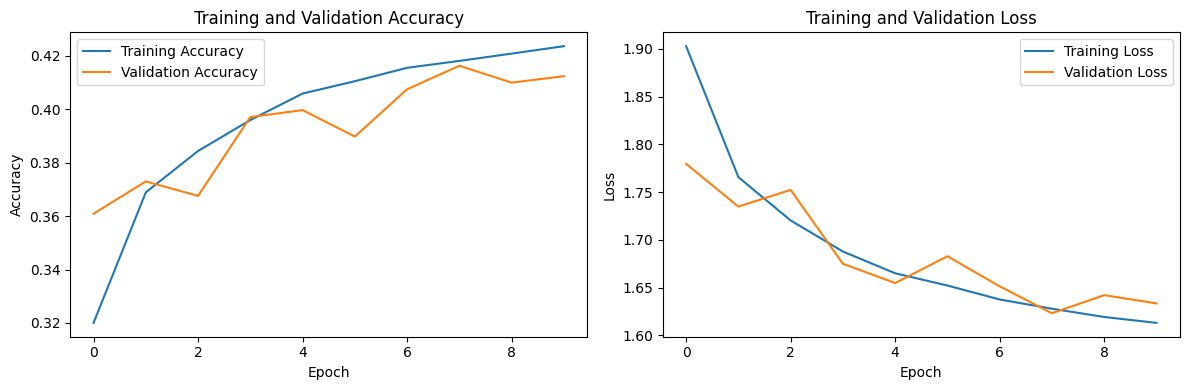

In [6]:
def plot_history(history):

    plt.figure(figsize=(12, 4))

    # Grafik Accuracy
    plt.subplot(1, 2, 1)

    plt.plot(
        history.history['accuracy'],
        label='Training Accuracy'
    )

    plt.plot(
        history.history['val_accuracy'],
        label='Validation Accuracy'
    )

    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Grafik Loss
    plt.subplot(1, 2, 2)

    plt.plot(
        history.history['loss'],
        label='Training Loss'
    )

    plt.plot(
        history.history['val_loss'],
        label='Validation Loss'
    )

    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()


plot_history(history)

Penjelasan:

Kamu akan mendapatkan dua grafik:
- Accuracy: memperlihatkan perkembangan kemampuan model dalam memprediksi gambar.
- Loss: memperlihatkan tingkat kesalahan model selama proses training dan validasi.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


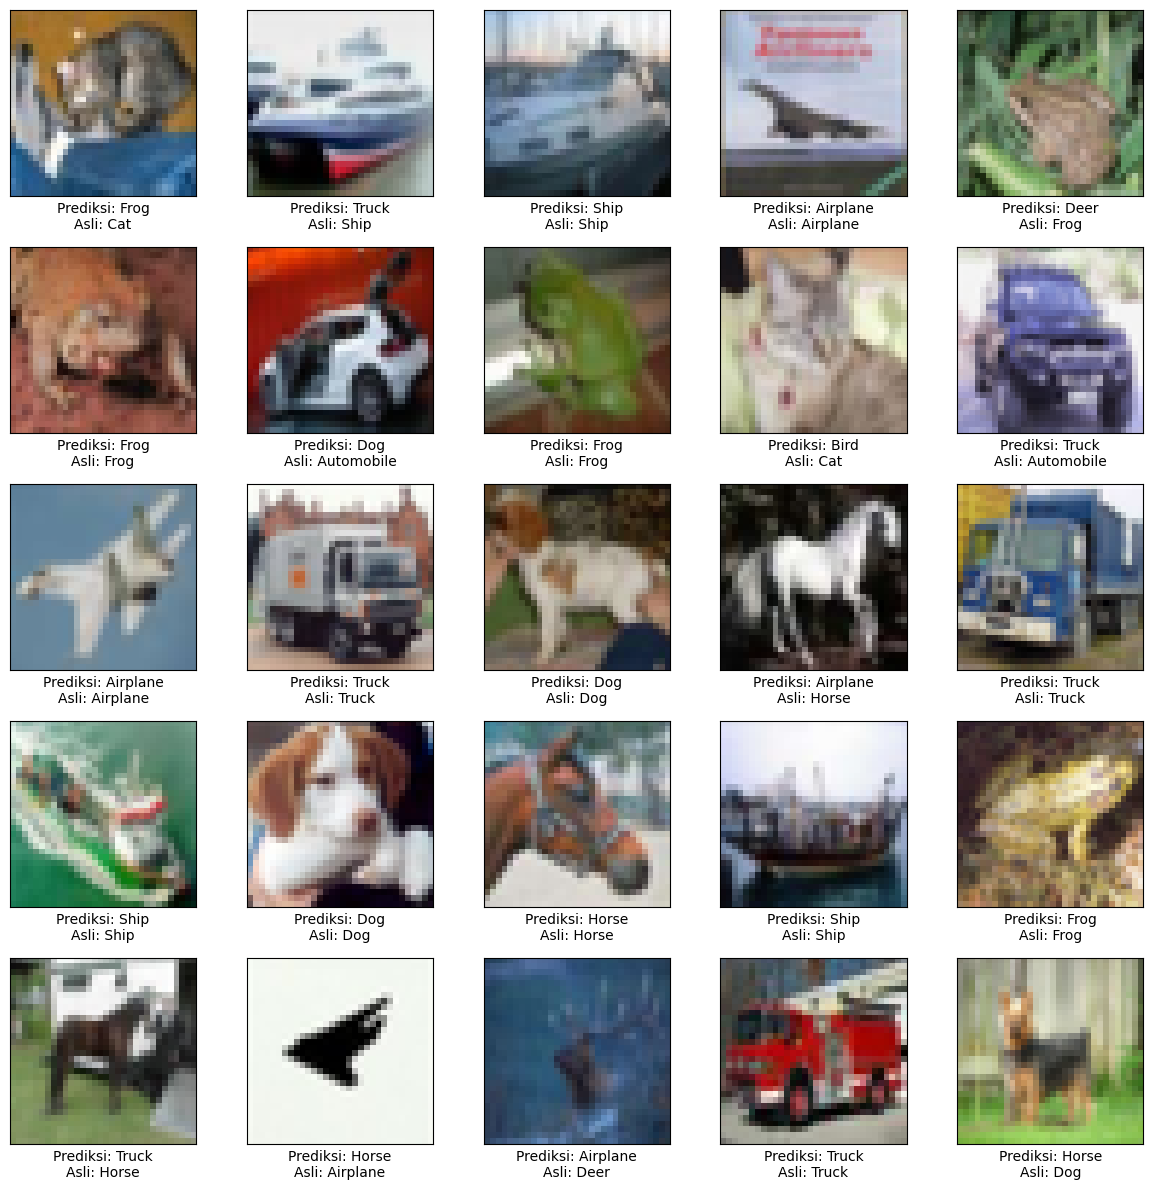

In [7]:
# Melakukan prediksi
predictions = model.predict(test_images[:25])

plt.figure(figsize=(12, 12))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    plt.imshow(test_images[i])

    predicted_label = np.argmax(predictions[i])
    actual_label = test_labels[i][0]

    plt.xlabel(
        f"Prediksi: {class_names[predicted_label]}\n"
        f"Asli: {class_names[actual_label]}"
    )

plt.tight_layout()
plt.show()

Penjelasan:

Model akan memprediksi kategori dari 25 gambar pertama pada data testing.

Contohnya:
- Prediksi: Cat
- Asli: Cat
Berarti prediksinya benar.

Jika:
- Prediksi: Dog
- Asli: Cat
Berarti model salah mengklasifikasikan gambar tersebut.